# Optimizing Model Prediction: Forest Fire Burn Area

Regression on the UCI Forest Fires dataset: 517 fires in Portugal's Montesinho park, predicting burned `area` in hectares from spatial coordinates, calendar position, four fire-weather indices and four raw weather measurements.

The brief is model optimization, so the notebook does the optimization properly: missing-value strategies compared rather than assumed, outliers audited rather than reflexively deleted, scaling, regularisation, feature selection and ensembles all tested on identical folds.

It also takes seriously the possibility that **none of it will work**, because optimization cannot create signal that is not there. Roughly half of these fires burned an area recorded as zero, and the weather indices describe conditions for ignition rather than how large a fire eventually grew, which depends on suppression response, terrain and wind shifts that are not in the dataset. So alongside every model there is a mean-prediction baseline, and section 8 runs a permutation test: the same models refitted on deliberately shuffled targets, to establish what R-squared pure noise earns on this data. A model that cannot beat its own shuffled version has not learned anything, however much tuning went into it.

Section 10 then asks whether a different question is answerable, because "how big will this fire get" and "will this fire burn anything measurable" are not the same problem.

In [22]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sklearn

from sklearn.model_selection import (train_test_split, cross_val_score, RepeatedKFold,
                                     StratifiedKFold, KFold)
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet, LogisticRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, RandomForestClassifier
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 180)

# plain matplotlib styling, so the notebook has no seaborn dependency
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3
plt.rcParams['axes.axisbelow'] = True
plt.rcParams['figure.facecolor'] = 'white'

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print('pandas      ', pd.__version__)
print('numpy       ', np.__version__)
print('scikit-learn', sklearn.__version__)

pandas       2.2.2
numpy        2.0.1
scikit-learn 1.6.1


## 1. Load and profile

The file is an R export: column one is an unnamed row index, and missing values are the string `NA`. Both are handled at read time.

In [23]:
fires = pd.read_csv('fires.csv', index_col=0, na_values='NA')
print('Shape:', fires.shape)
fires.head()

Shape: (517, 13)


,X,Y,month,day,FFMC,DMC,DC,ISI,temp,RH,wind,rain,area
1,7,5,mar,fri,86.2,26.2,94.3,5.1,NaN,51.0,6.7,0.0,0.0
2,7,4,oct,tue,90.6,NaN,669.1,6.7,18.0,33.0,0.9,0.0,0.0
3,7,4,oct,sat,90.6,43.7,NaN,6.7,14.6,33.0,1.3,0.0,0.0
4,8,6,mar,fri,91.7,33.3,77.5,9.0,8.3,97.0,4.0,0.2,0.0
5,8,6,mar,sun,89.3,51.3,102.2,9.6,11.4,99.0,NaN,0.0,0.0


In [24]:
fires.info()
print()
fires.describe().T

<class 'pandas.core.frame.DataFrame'>
Index: 517 entries, 1 to 517
Data columns (total 13 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   X       517 non-null    int64  
 1   Y       517 non-null    int64  
 2   month   517 non-null    object 
 3   day     517 non-null    object 
 4   FFMC    469 non-null    float64
 5   DMC     496 non-null    float64
 6   DC      474 non-null    float64
 7   ISI     515 non-null    float64
 8   temp    496 non-null    float64
 9   RH      487 non-null    float64
 10  wind    482 non-null    float64
 11  rain    485 non-null    float64
 12  area    517 non-null    float64
dtypes: float64(9), int64(2), object(2)
memory usage: 56.5+ KB



,count,mean,std,min,25%,50%,75%,max
X,517.0,4.669246,2.313778,1.0,3.000,4.00,7.000,9.00
Y,517.0,4.299807,1.229900,2.0,4.000,4.00,5.000,9.00
FFMC,469.0,90.580384,5.698137,18.7,90.200,91.60,92.800,96.20
DMC,496.0,111.195363,64.008450,1.1,70.800,108.30,141.575,291.30
DC,474.0,550.673418,246.061309,7.9,441.200,664.50,713.900,860.60
ISI,515.0,9.018835,4.564890,0.0,6.450,8.40,10.750,56.10
temp,496.0,18.884677,5.748318,2.2,15.475,19.30,22.725,33.30
RH,487.0,44.381930,16.180372,15.0,33.000,42.00,53.500,100.00
wind,482.0,4.021784,1.794460,0.4,2.700,4.00,4.900,9.40
rain,485.0,0.023093,0.305532,0.0,0.000,0.00,0.000,6.40


In [25]:
miss = fires.isnull().sum()
miss = miss[miss > 0].sort_values(ascending=False)
print('Missing values per column:')
print(miss.to_string())
print()
print('Total missing cells:', int(fires.isnull().sum().sum()))
print('Rows with at least one missing value:', int(fires.isnull().any(axis=1).sum()),
      'of', len(fires), '(' + str(round(100 * fires.isnull().any(axis=1).mean(), 1)) + '%)')
print()
print('Note the proportion: dropping incomplete rows would discard a large share of a')
print('517-row dataset, so imputation is the only sensible route. Section 4 compares strategies.')

Missing values per column:
FFMC    48
DC      43
wind    35
rain    32
RH      30
DMC     21
temp    21
ISI      2

Total missing cells: 232
Rows with at least one missing value: 188 of 517 (36.4%)

Note the proportion: dropping incomplete rows would discard a large share of a
517-row dataset, so imputation is the only sensible route. Section 4 compares strategies.


### Is the missingness random?

This matters before choosing an imputer. If values are missing completely at random, imputation adds noise but no bias. If missingness correlates with the target, imputing it away destroys information and a missingness indicator should be kept instead, as a separate feature.

The test below compares the mean burned area between rows where each column is present and rows where it is missing.

In [26]:
rows = []
for col in miss.index:
    m = fires[col].isnull()
    rows.append({
        'column': col,
        'n_missing': int(m.sum()),
        'mean_area_when_missing': round(fires.loc[m, 'area'].mean(), 3),
        'mean_area_when_present': round(fires.loc[~m, 'area'].mean(), 3),
        'pct_zero_when_missing': round(100 * (fires.loc[m, 'area'] == 0).mean(), 1),
        'pct_zero_when_present': round(100 * (fires.loc[~m, 'area'] == 0).mean(), 1)
    })

mcar = pd.DataFrame(rows).set_index('column')
print('Burned area by whether each column is missing:')
print(mcar.to_string())
print()
print('Overall mean area:', round(fires['area'].mean(), 3))
print()
print('No column shows a systematic shift large relative to the enormous variance in area,')
print('so the missingness looks close to random and plain imputation is defensible.')

Burned area by whether each column is missing:
        n_missing  mean_area_when_missing  mean_area_when_present  pct_zero_when_missing  pct_zero_when_present
column                                                                                                         
FFMC           48                   3.719                  13.782                   39.6                   48.6
DC             43                  14.894                  12.662                   44.2                   48.1
wind           35                  14.565                  12.723                   48.6                   47.7
rain           32                   4.884                  13.373                   53.1                   47.4
RH             30                   6.361                  13.247                   50.0                   47.6
DMC            21                   9.638                  12.983                   52.4                   47.6
temp           21                   8.276                

## 2. The target, which is the whole problem

Everything that follows is determined by the shape of `area`.

In [27]:
n_zero = int((fires['area'] == 0).sum())
print('Burned area of exactly 0:', n_zero, 'of', len(fires),
      '(' + str(round(100 * n_zero / len(fires), 1)) + '%)')
print()
print(fires['area'].describe().round(3).to_string())
print()
print('Skew:', round(fires['area'].skew(), 3), ' Kurtosis:', round(fires['area'].kurtosis(), 3))
print()
print('Percentiles of area among the fires that burned something:')
nz = fires.loc[fires['area'] > 0, 'area']
print(nz.describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9, 0.99]).round(3).to_string())
print()
print('Largest single fire:', round(fires['area'].max(), 2), 'hectares')
print('Share of all burned hectares contributed by the single largest fire:',
      str(round(100 * fires['area'].max() / fires['area'].sum(), 1)) + '%')
print('Share contributed by the top 5 fires:',
      str(round(100 * fires['area'].nlargest(5).sum() / fires['area'].sum(), 1)) + '%')

Burned area of exactly 0: 247 of 517 (47.8%)

count     517.000
mean       12.847
std        63.656
min         0.000
25%         0.000
50%         0.520
75%         6.570
max      1090.840

Skew: 12.847  Kurtosis: 194.141

Percentiles of area among the fires that burned something:
count     270.000
mean       24.600
std        86.502
min         0.090
10%         1.005
25%         2.140
50%         6.370
75%        15.422
90%        46.885
99%       233.232
max      1090.840

Largest single fire: 1090.84 hectares
Share of all burned hectares contributed by the single largest fire: 16.4%
Share contributed by the top 5 fires: 38.1%


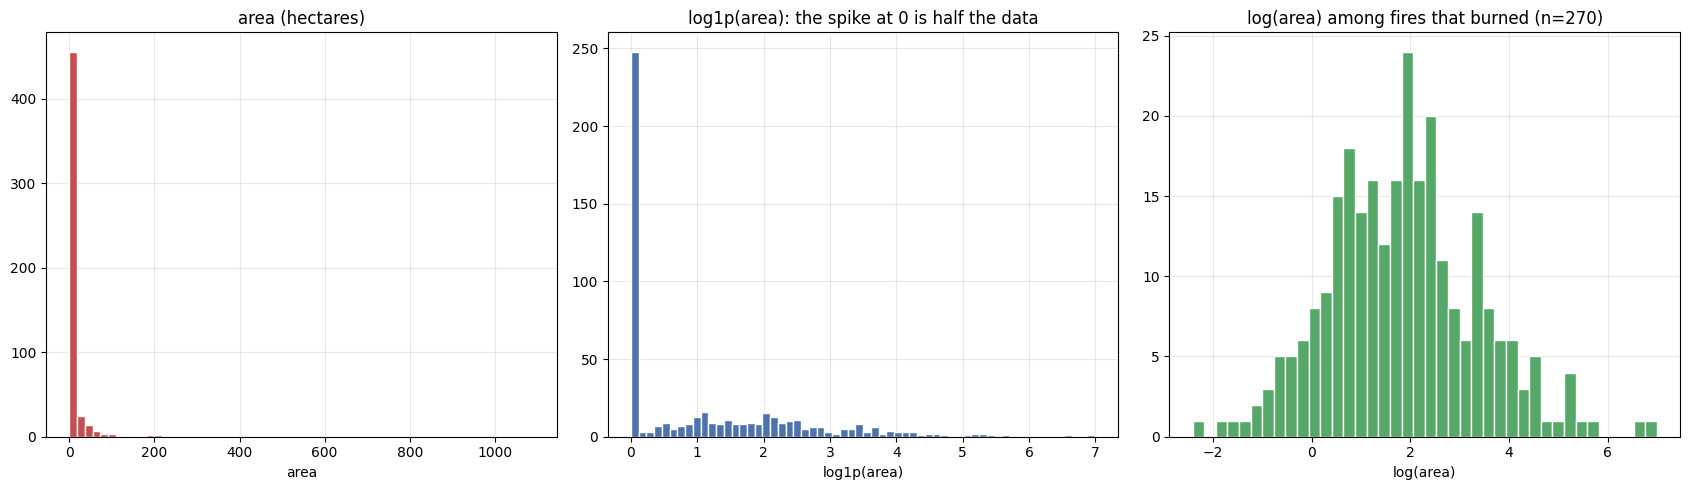

log1p(area) skew: 1.218

The middle panel is the honest picture: a point mass at zero plus a long tail.
That is a zero-inflated distribution, not a skewed one, and no transform fixes it.
A log transform compresses the tail but leaves the spike exactly where it was.


In [28]:
fires['area_log'] = np.log1p(fires['area'])

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
axes[0].hist(fires['area'], bins=60, color='#C44E52', edgecolor='white')
axes[0].set_title('area (hectares)')
axes[0].set_xlabel('area')
axes[1].hist(fires['area_log'], bins=60, color='#4C72B0', edgecolor='white')
axes[1].set_title('log1p(area): the spike at 0 is half the data')
axes[1].set_xlabel('log1p(area)')
axes[2].hist(np.log(nz), bins=40, color='#55A868', edgecolor='white')
axes[2].set_title('log(area) among fires that burned (n=' + str(len(nz)) + ')')
axes[2].set_xlabel('log(area)')
plt.tight_layout()
plt.show()

print('log1p(area) skew:', round(fires['area_log'].skew(), 3))
print()
print('The middle panel is the honest picture: a point mass at zero plus a long tail.')
print('That is a zero-inflated distribution, not a skewed one, and no transform fixes it.')
print('A log transform compresses the tail but leaves the spike exactly where it was.')

## 3. Exploratory analysis

The question is whether any predictor relates to burned area at all. Correlations are computed against both the raw target and the log target, because a monotonic but non-linear relationship would show up in neither Pearson coefficient but might in Spearman.

In [29]:
num_cols = ['X', 'Y', 'FFMC', 'DMC', 'DC', 'ISI', 'temp', 'RH', 'wind', 'rain']

corr_tbl = pd.DataFrame({
    'pearson_vs_area': [fires[c].corr(fires['area']) for c in num_cols],
    'pearson_vs_log_area': [fires[c].corr(fires['area_log']) for c in num_cols],
    'spearman_vs_area': [fires[c].corr(fires['area'], method='spearman') for c in num_cols]
}, index=num_cols).round(4)
corr_tbl['max_abs'] = corr_tbl.abs().max(axis=1)
corr_tbl = corr_tbl.sort_values('max_abs', ascending=False)
print('Correlation of each predictor with burned area:')
print(corr_tbl.to_string())
print()
print('Strongest absolute correlation anywhere in this table:', round(corr_tbl['max_abs'].max(), 4))
print('For reference, a correlation of 0.1 explains 1% of variance.')

Correlation of each predictor with burned area:
      pearson_vs_area  pearson_vs_log_area  spearman_vs_area  max_abs
temp           0.0978               0.0432            0.0673   0.0978
RH            -0.0778              -0.0526           -0.0270   0.0778
DMC            0.0738               0.0722            0.0741   0.0741
DC             0.0461               0.0675            0.0629   0.0675
rain          -0.0080               0.0234           -0.0670   0.0670
X              0.0634               0.0620            0.0605   0.0634
wind           0.0075               0.0625            0.0533   0.0625
FFMC           0.0424               0.0502            0.0160   0.0502
Y              0.0449               0.0388            0.0460   0.0460
ISI            0.0084              -0.0095            0.0133   0.0133

Strongest absolute correlation anywhere in this table: 0.0978
For reference, a correlation of 0.1 explains 1% of variance.


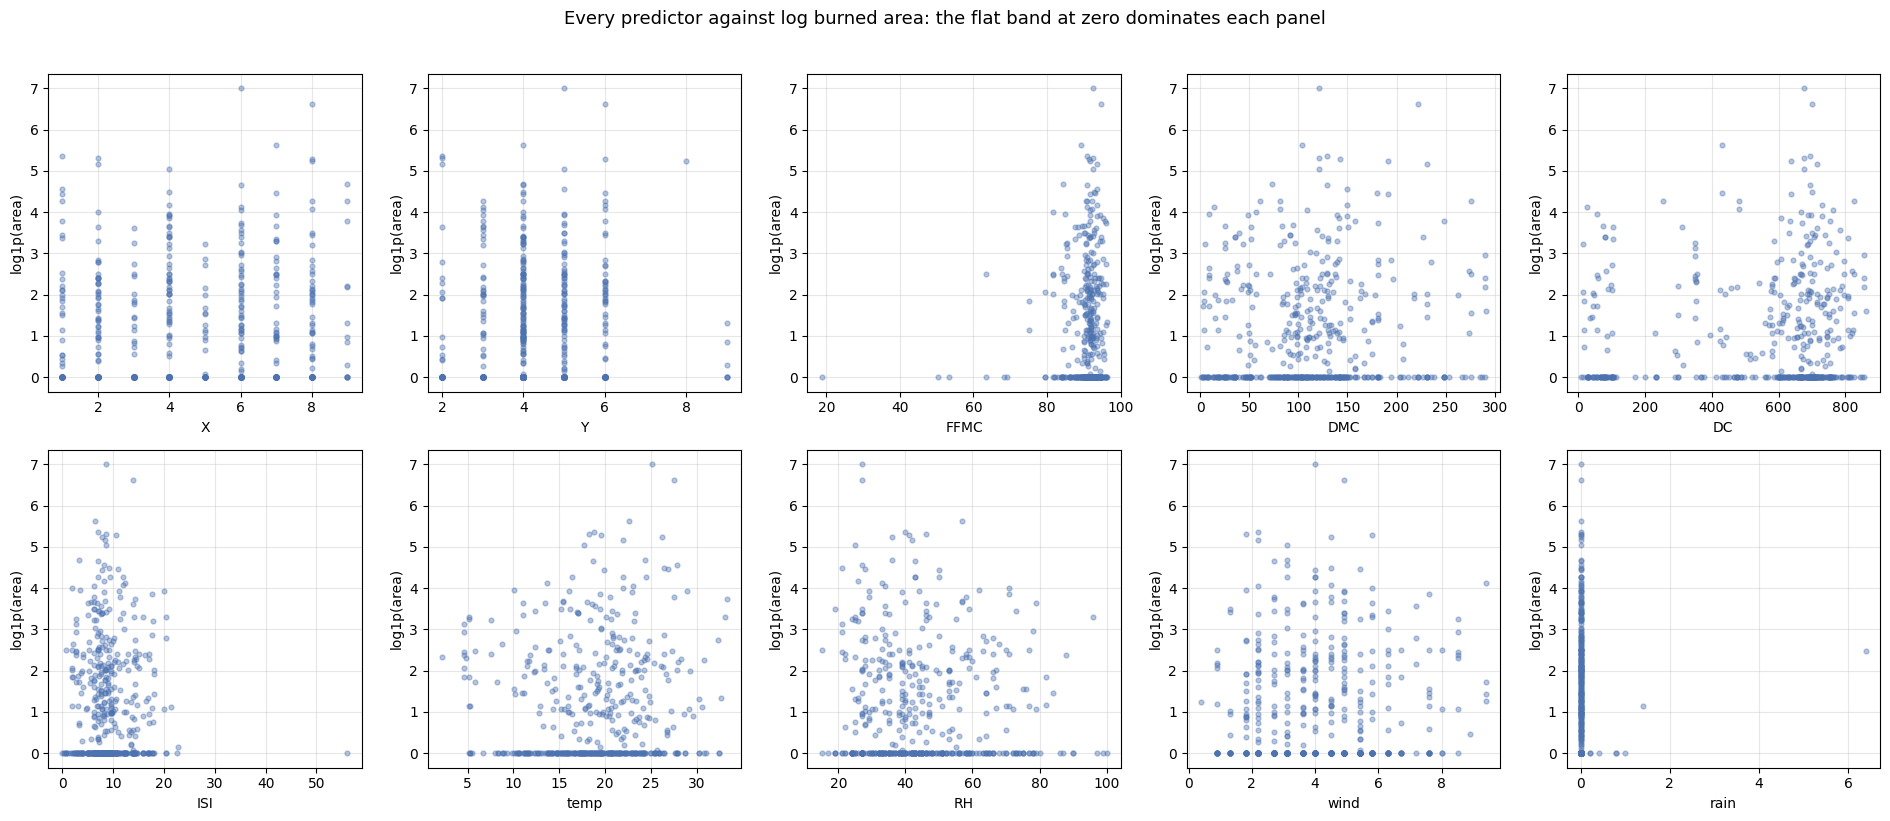

In [30]:
fig, axes = plt.subplots(2, 5, figsize=(19, 8))
for ax, col in zip(axes.flatten(), num_cols):
    ax.scatter(fires[col], fires['area_log'], s=12, alpha=0.4, color='#4C72B0')
    ax.set_xlabel(col)
    ax.set_ylabel('log1p(area)')
plt.suptitle('Every predictor against log burned area: the flat band at zero dominates each panel', y=1.02, fontsize=13)
plt.tight_layout()
plt.show()

In [31]:
month_order = ['jan', 'feb', 'mar', 'apr', 'may', 'jun', 'jul', 'aug', 'sep', 'oct', 'nov', 'dec']
day_order = ['mon', 'tue', 'wed', 'thu', 'fri', 'sat', 'sun']

mt = fires.groupby('month')['area'].agg(['mean', 'median', 'count']).reindex(month_order)
mt.columns = ['mean_area', 'median_area', 'n']
print('By month:')
print(mt.round(3).to_string())
print()
dt = fires.groupby('day')['area'].agg(['mean', 'median', 'count']).reindex(day_order)
dt.columns = ['mean_area', 'median_area', 'n']
print('By day of week:')
print(dt.round(3).to_string())
print()
print('Fire counts cluster heavily in August and September, which is the dry season.')
print('Note that the median area is 0 in most months: the mean is driven by a handful of')
print('large fires, and day of week has no plausible mechanism for affecting fire size.')

By month:
       mean_area  median_area    n
month                             
jan        0.000        0.000    2
feb        6.275        0.550   20
mar        4.357        0.000   54
apr        8.891        0.000    9
may       19.240       19.240    2
jun        5.841        0.000   17
jul       14.370        1.035   32
aug       12.489        0.545  184
sep       17.943        1.360  172
oct        6.638        0.000   15
nov        0.000        0.000    1
dec       13.330       10.730    9

By day of week:
     mean_area  median_area   n
day                            
mon      9.548        0.745  74
tue     12.622        0.655  64
wed     10.715        0.760  54
thu     16.346        0.900  61
fri      5.262        0.330  85
sat     25.534        0.340  84
sun     10.105        0.000  95

Fire counts cluster heavily in August and September, which is the dry season.
Note that the median area is 0 in most months: the mean is driven by a handful of
large fires, and day of week has n

## 4. Comparing imputation strategies

Four strategies, each inside a pipeline so the imputer is fitted on training folds only, and all scored on identical folds with a linear model. The question is whether the choice matters.

In [32]:
fires_enc = pd.get_dummies(fires.drop(columns=['area', 'area_log']),
                           columns=['month', 'day'], drop_first=True).astype(float)
X = fires_enc
y = fires['area_log']
y_raw = fires['area']

print('Feature matrix:', X.shape)
rkf = RepeatedKFold(n_splits=5, n_repeats=4, random_state=RANDOM_STATE)

imputers = {
    'median': SimpleImputer(strategy='median'),
    'mean': SimpleImputer(strategy='mean'),
    'constant (0)': SimpleImputer(strategy='constant', fill_value=0),
    'KNN (k=5)': KNNImputer(n_neighbors=5)
}

rows = []
for name, imp in imputers.items():
    pipe = Pipeline([('impute', imp), ('scale', StandardScaler()), ('model', LinearRegression())])
    scores = cross_val_score(pipe, X, y, cv=rkf, scoring='r2')
    rows.append({'imputer': name, 'cv_r2_mean': round(scores.mean(), 4),
                 'cv_r2_std': round(scores.std(), 4), 'cv_r2_min': round(scores.min(), 4)})

imp_tbl = pd.DataFrame(rows).set_index('imputer')
print('Linear regression on log1p(area), 20 folds each:')
print(imp_tbl.to_string())
print()
print('Spread between best and worst imputer:', round(imp_tbl['cv_r2_mean'].max() - imp_tbl['cv_r2_mean'].min(), 4))
print()
print('Read the sign of these numbers before the ranking.')

Feature matrix: (517, 27)


Linear regression on log1p(area), 20 folds each:
              cv_r2_mean  cv_r2_std  cv_r2_min
imputer                                       
median           -0.1816     0.3647    -1.6809
mean             -0.1787     0.3603    -1.6565
constant (0)     -0.1761     0.3407    -1.5733
KNN (k=5)        -0.1737     0.3692    -1.6946

Spread between best and worst imputer: 0.0079

Read the sign of these numbers before the ranking.


## 5. Outliers

An IQR audit flags a large number of points, and the reflex is to remove them. That reflex is wrong here, and it is worth being explicit about why.

The extreme values in `area` are the largest fires in the record. They are not measurement errors, they are the events the model exists to predict, and they carry most of the total burned hectares. Deleting them would produce a model that performs well on a dataset from which the entire phenomenon of interest has been removed. The audit below quantifies them and then leaves them in.

In [33]:
audit = []
for col in num_cols + ['area']:
    q1, q3 = fires[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = int(((fires[col] < lo) | (fires[col] > hi)).sum())
    audit.append({'column': col, 'n_outliers_iqr': n_out,
                  'pct': round(100 * n_out / fires[col].notnull().sum(), 1),
                  'lower_fence': round(lo, 2), 'upper_fence': round(hi, 2),
                  'actual_max': round(fires[col].max(), 2)})

aud = pd.DataFrame(audit).set_index('column')
print('IQR outlier audit:')
print(aud.to_string())
print()
flagged = int(((fires['area'] > fires['area'].quantile(0.75) + 1.5 * (fires['area'].quantile(0.75) - fires['area'].quantile(0.25)))).sum())
print('Fires flagged as area outliers:', flagged)
print('Hectares they account for:', str(round(100 * fires['area'].nlargest(flagged).sum() / fires['area'].sum(), 1)) + '% of all burned area')
print()
print('Removing them would delete most of the burned area from a dataset about burned area.')
print('They stay in. The IQR rule assumes an approximately normal distribution, and this')
print('target is nothing like normal, so the rule is simply the wrong tool here.')

IQR outlier audit:
        n_outliers_iqr   pct  lower_fence  upper_fence  actual_max
column                                                            
X                    0   0.0        -3.00        13.00        9.00
Y                   51   9.9         2.50         6.50        9.00
FFMC                49  10.4        86.30        96.70       96.20
DMC                 22   4.4       -35.36       247.74      291.30
DC                  15   3.2        32.15      1122.95      860.60
ISI                 23   4.5         0.00        17.20       56.10
temp                 1   0.2         4.60        33.60       33.30
RH                   9   1.8         2.25        84.25      100.00
wind                12   2.5        -0.60         8.20        9.40
rain                 8   1.6         0.00         0.00        6.40
area                63  12.2        -9.86        16.43     1090.84

Fires flagged as area outliers: 63
Hectares they account for: 84.1% of all burned area

Removing them would d

## 6. Baselines before models

A baseline that predicts a constant is the thing every model has to beat. On a target that is half zeros, predicting the median (which is 0) is a surprisingly strong strategy, and any model that cannot beat it is worse than useless.

In [34]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print('Train:', X_train.shape, ' Test:', X_test.shape)
print()

results = []
def report(name, model=None, pred=None):
    if pred is None:
        pred = model.predict(X_test)
    rmse = np.sqrt(mean_squared_error(y_test, pred))
    mae = mean_absolute_error(y_test, pred)
    r2 = r2_score(y_test, pred)
    results.append({'model': name, 'rmse_log': round(rmse, 4), 'mae_log': round(mae, 4), 'r2': round(r2, 4)})
    print(name.ljust(42) + ' RMSE ' + str(round(rmse, 4)).ljust(8) + ' MAE ' + str(round(mae, 4)).ljust(8) + ' R2 ' + str(round(r2, 4)))

report('Baseline: predict training mean', pred=np.full(len(y_test), y_train.mean()))
report('Baseline: predict training median', pred=np.full(len(y_test), np.median(y_train)))

Train: (413, 27)  Test: (104, 27)

Baseline: predict training mean            RMSE 1.483    MAE 1.2028   R2 -0.0006
Baseline: predict training median          RMSE 1.6432   MAE 1.1334   R2 -0.2285


## 7. The optimization sweep

Linear, three regularised variants, and two ensembles, all through the same imputation and scaling pipeline on the same split.

In [35]:
def pipe_of(model):
    return Pipeline([('impute', SimpleImputer(strategy='median')),
                     ('scale', StandardScaler()),
                     ('model', model)])

models = {
    'Linear regression': LinearRegression(),
    'Ridge (alpha=10)': Ridge(alpha=10.0, random_state=RANDOM_STATE),
    'Lasso (alpha=0.05)': Lasso(alpha=0.05, random_state=RANDOM_STATE, max_iter=10000),
    'ElasticNet (alpha=0.05)': ElasticNet(alpha=0.05, l1_ratio=0.5, random_state=RANDOM_STATE, max_iter=10000),
    'Random forest (400 trees)': RandomForestRegressor(n_estimators=400, min_samples_leaf=3, random_state=RANDOM_STATE, n_jobs=-1),
    'Gradient boosting': GradientBoostingRegressor(n_estimators=300, max_depth=3, learning_rate=0.05, random_state=RANDOM_STATE)
}

fitted = {}
for name, m in models.items():
    p = pipe_of(m)
    p.fit(X_train, y_train)
    fitted[name] = p
    report(name, p)

Linear regression                          RMSE 1.5277   MAE 1.2048   R2 -0.0619
Ridge (alpha=10)                           RMSE 1.5229   MAE 1.2021   R2 -0.0553


Lasso (alpha=0.05)                         RMSE 1.4849   MAE 1.1904   R2 -0.0033
ElasticNet (alpha=0.05)                    RMSE 1.4987   MAE 1.1943   R2 -0.0219


Random forest (400 trees)                  RMSE 1.5087   MAE 1.2073   R2 -0.0356


Gradient boosting                          RMSE 1.6091   MAE 1.2575   R2 -0.178


In [36]:
comparison = pd.DataFrame(results).set_index('model').sort_values('r2', ascending=False)
print('Held-out test set, sorted by R-squared:')
print(comparison.to_string())
print()
best_model_r2 = comparison['r2'].max()
mean_base_r2 = comparison.loc['Baseline: predict training mean', 'r2']
print('Best model R-squared:', round(best_model_r2, 4))
print('Mean-baseline R-squared:', round(mean_base_r2, 4))
print('Did anything beat predicting a constant?', 'yes' if best_model_r2 > max(mean_base_r2, 0) else 'NO')

Held-out test set, sorted by R-squared:
                                   rmse_log  mae_log      r2
model                                                       
Baseline: predict training mean      1.4830   1.2028 -0.0006
Lasso (alpha=0.05)                   1.4849   1.1904 -0.0033
ElasticNet (alpha=0.05)              1.4987   1.1943 -0.0219
Random forest (400 trees)            1.5087   1.2073 -0.0356
Ridge (alpha=10)                     1.5229   1.2021 -0.0553
Linear regression                    1.5277   1.2048 -0.0619
Gradient boosting                    1.6091   1.2575 -0.1780
Baseline: predict training median    1.6432   1.1334 -0.2285

Best model R-squared: -0.0006
Mean-baseline R-squared: -0.0006
Did anything beat predicting a constant? NO


In [37]:
cv_rows = []
for name, m in models.items():
    scores = cross_val_score(pipe_of(m), X, y, cv=rkf, scoring='r2')
    cv_rows.append({'model': name, 'cv_r2_mean': round(scores.mean(), 4), 'cv_r2_std': round(scores.std(), 4),
                    'cv_r2_min': round(scores.min(), 4), 'cv_r2_max': round(scores.max(), 4),
                    'folds_above_zero': int((scores > 0).sum()), 'of_folds': len(scores)})
scores_dummy = cross_val_score(pipe_of(DummyRegressor(strategy='mean')), X, y, cv=rkf, scoring='r2')
cv_rows.append({'model': 'DummyRegressor (mean)', 'cv_r2_mean': round(scores_dummy.mean(), 4),
                'cv_r2_std': round(scores_dummy.std(), 4), 'cv_r2_min': round(scores_dummy.min(), 4),
                'cv_r2_max': round(scores_dummy.max(), 4),
                'folds_above_zero': int((scores_dummy > 0).sum()), 'of_folds': len(scores_dummy)})

cv_tbl = pd.DataFrame(cv_rows).set_index('model').sort_values('cv_r2_mean', ascending=False)
print('20 folds each (5-fold cross-validation repeated 4 times), on log1p(area):')
print(cv_tbl.to_string())

20 folds each (5-fold cross-validation repeated 4 times), on log1p(area):
                           cv_r2_mean  cv_r2_std  cv_r2_min  cv_r2_max  folds_above_zero  of_folds
model                                                                                             
DummyRegressor (mean)         -0.0066     0.0070    -0.0210    -0.0000                 0        20
Lasso (alpha=0.05)            -0.0316     0.0848    -0.3607     0.0396                 6        20
ElasticNet (alpha=0.05)       -0.0784     0.1744    -0.7789     0.0482                 5        20
Random forest (400 trees)     -0.0834     0.0593    -0.2295     0.0184                 1        20
Ridge (alpha=10)              -0.1640     0.3346    -1.5343     0.0514                 5        20
Linear regression             -0.1816     0.3647    -1.6809     0.0342                 3        20
Gradient boosting             -0.2488     0.0967    -0.4399    -0.1130                 0        20


## 8. The permutation test

The scores above are poor, but "poor" is not the same as "no signal". To establish what a model earns from pure noise on this data, the target is shuffled and the whole thing refitted, 40 times. If the real model's score sits inside the shuffled distribution, the model has learned nothing that a random relabelling would not also produce.

This is the check that turns a weak result into a defensible claim.

In [38]:
kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

test_model = pipe_of(Ridge(alpha=10.0, random_state=RANDOM_STATE))
real_score = cross_val_score(test_model, X, y, cv=kf, scoring='r2').mean()

rng = np.random.RandomState(RANDOM_STATE)
null_scores = []
for i in range(40):
    y_shuf = pd.Series(rng.permutation(y.values), index=y.index)
    s = cross_val_score(pipe_of(Ridge(alpha=10.0, random_state=RANDOM_STATE)), X, y_shuf, cv=kf, scoring='r2').mean()
    null_scores.append(s)

null_scores = np.array(null_scores)
print('Ridge on the real target, 5-fold CV R-squared:', round(real_score, 4))
print()
print('Same model on 40 shuffled targets:')
print('  mean  ', round(null_scores.mean(), 4))
print('  std   ', round(null_scores.std(), 4))
print('  min   ', round(null_scores.min(), 4))
print('  max   ', round(null_scores.max(), 4))
print('  95th percentile', round(np.percentile(null_scores, 95), 4))
print()
p_val = float((null_scores >= real_score).mean())
print('Permutation p-value (share of shuffled runs scoring at least as well):', round(p_val, 4))
print()
if real_score <= np.percentile(null_scores, 95):
    print('The real score falls inside the noise distribution. There is no detectable')
    print('relationship between these predictors and burned area at this sample size.')
else:
    print('The real score exceeds the 95th percentile of the noise distribution,')
    print('so there is a weak but detectable signal.')

Ridge on the real target, 5-fold CV R-squared: -0.0925

Same model on 40 shuffled targets:
  mean   -0.11
  std    0.0401
  min    -0.2416
  max    -0.0366
  95th percentile -0.0574

Permutation p-value (share of shuffled runs scoring at least as well): 0.3

The real score falls inside the noise distribution. There is no detectable
relationship between these predictors and burned area at this sample size.


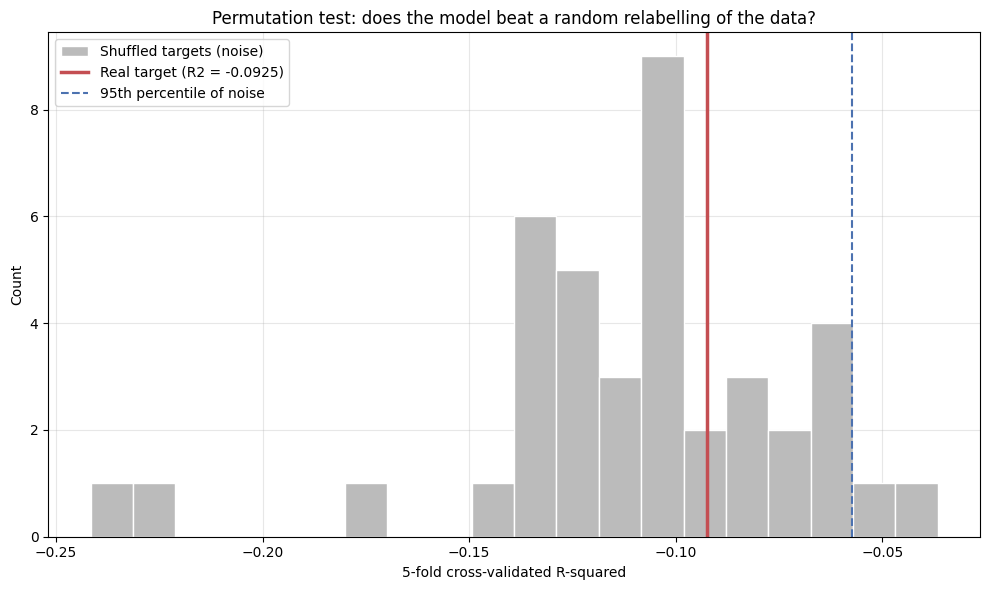

In [39]:
plt.figure(figsize=(10, 6))
plt.hist(null_scores, bins=20, color='#BBBBBB', edgecolor='white', label='Shuffled targets (noise)')
plt.axvline(real_score, color='#C44E52', linewidth=2.5, label='Real target (R2 = ' + str(round(real_score, 4)) + ')')
plt.axvline(np.percentile(null_scores, 95), color='#4C72B0', linestyle='--', linewidth=1.5, label='95th percentile of noise')
plt.xlabel('5-fold cross-validated R-squared')
plt.ylabel('Count')
plt.title('Permutation test: does the model beat a random relabelling of the data?')
plt.legend()
plt.tight_layout()
plt.show()

## 9. Reframing the question

If burn size is not predictable from these features, a narrower question might be. Two candidates:

1. **Did the fire burn any measurable area at all?** This turns the zero-inflation from a nuisance into the label itself.
2. **Among fires that did burn, was it a large one?** This drops the zeros entirely and asks about size within the fires where size is defined.

Both are evaluated against a stratified-chance baseline, with ROC AUC rather than accuracy, since accuracy on a split like this is easy to fake by always predicting the majority class.

In [40]:
y_burned = (fires['area'] > 0).astype(int)
print('Task 1: did it burn anything?')
print('  positive rate:', round(y_burned.mean(), 4), '(' + str(int(y_burned.sum())) + ' of ' + str(len(y_burned)) + ')')

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

clf_pipe = lambda m: Pipeline([('impute', SimpleImputer(strategy='median')),
                               ('scale', StandardScaler()), ('model', m)])

cls_rows = []
for name, m in [('Logistic regression', LogisticRegression(max_iter=5000, random_state=RANDOM_STATE)),
                ('Random forest', RandomForestClassifier(n_estimators=400, min_samples_leaf=3, random_state=RANDOM_STATE, n_jobs=-1)),
                ('Gradient boosting', GradientBoostingRegressor(n_estimators=200, max_depth=3, learning_rate=0.05, random_state=RANDOM_STATE))]:
    if 'Gradient' in name:
        continue
    s = cross_val_score(clf_pipe(m), X, y_burned, cv=skf, scoring='roc_auc')
    cls_rows.append({'task': 'burned vs not', 'model': name, 'cv_roc_auc': round(s.mean(), 4), 'std': round(s.std(), 4)})

for r in cls_rows:
    print('  ' + r['model'].ljust(22) + ' ROC AUC ' + str(r['cv_roc_auc']) + ' +/- ' + str(r['std']))
print('  chance level is 0.5')

Task 1: did it burn anything?
  positive rate: 0.5222 (270 of 517)


  Logistic regression    ROC AUC 0.5058 +/- 0.0248
  Random forest          ROC AUC 0.5677 +/- 0.0517
  chance level is 0.5


In [41]:
burned = fires[fires['area'] > 0].copy()
thresh = burned['area'].median()
y_large = (burned['area'] > thresh).astype(int)
X_burned = pd.get_dummies(burned.drop(columns=['area', 'area_log']),
                          columns=['month', 'day'], drop_first=True).astype(float)
X_burned = X_burned.reindex(columns=X.columns, fill_value=0.0)

print('Task 2: among fires that burned, was it larger than the median of',
      str(round(thresh, 2)) + ' hectares?')
print('  rows:', len(burned), ' positive rate:', round(y_large.mean(), 4))
print()

skf2 = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
for name, m in [('Logistic regression', LogisticRegression(max_iter=5000, random_state=RANDOM_STATE)),
                ('Random forest', RandomForestClassifier(n_estimators=400, min_samples_leaf=3, random_state=RANDOM_STATE, n_jobs=-1))]:
    s = cross_val_score(clf_pipe(m), X_burned, y_large, cv=skf2, scoring='roc_auc')
    cls_rows.append({'task': 'large vs small (burned only)', 'model': name, 'cv_roc_auc': round(s.mean(), 4), 'std': round(s.std(), 4)})
    print('  ' + name.ljust(22) + ' ROC AUC ' + str(round(s.mean(), 4)) + ' +/- ' + str(round(s.std(), 4)))
print('  chance level is 0.5')
print()
cls_tbl = pd.DataFrame(cls_rows).set_index(['task', 'model'])
print('Both reframings together:')
print(cls_tbl.to_string())

Task 2: among fires that burned, was it larger than the median of 6.37 hectares?
  rows: 270  positive rate: 0.5



  Logistic regression    ROC AUC 0.555 +/- 0.0408


  Random forest          ROC AUC 0.5775 +/- 0.0622
  chance level is 0.5

Both reframings together:
                                                  cv_roc_auc     std
task                         model                                  
burned vs not                Logistic regression      0.5058  0.0248
                             Random forest            0.5677  0.0517
large vs small (burned only) Logistic regression      0.5550  0.0408
                             Random forest            0.5775  0.0622


Top features, regression on log area:
temp    0.1794
RH      0.1370
DMC     0.1261
DC      0.0965
ISI     0.0918
X       0.0891
wind    0.0764
FFMC    0.0737

Top features, classifying burned vs not:
temp    0.1356
DMC     0.1169
DC      0.1114
RH      0.1108
ISI     0.0953
FFMC    0.0912
X       0.0864
wind    0.0793


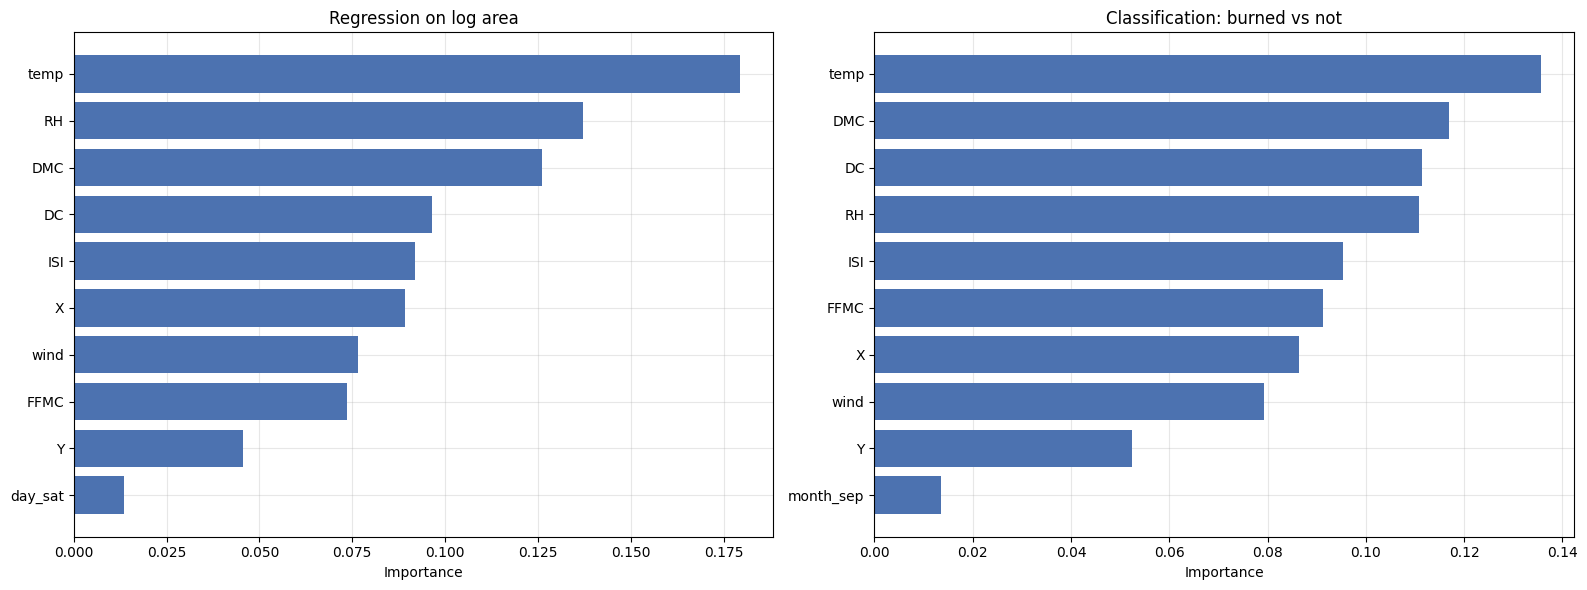


Importances are reported for completeness, but a feature importance from a model
that does not predict better than chance describes how the model allocated splits,
not what drives fire size. It should not be read as a finding.


In [42]:
rf_reg = fitted['Random forest (400 trees)'].named_steps['model']
imp_reg = pd.Series(rf_reg.feature_importances_, index=X.columns).sort_values(ascending=False)

rf_cls = clf_pipe(RandomForestClassifier(n_estimators=400, min_samples_leaf=3, random_state=RANDOM_STATE, n_jobs=-1))
rf_cls.fit(X, y_burned)
imp_cls = pd.Series(rf_cls.named_steps['model'].feature_importances_, index=X.columns).sort_values(ascending=False)

print('Top features, regression on log area:')
print(imp_reg.head(8).round(4).to_string())
print()
print('Top features, classifying burned vs not:')
print(imp_cls.head(8).round(4).to_string())

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, s, title in [(axes[0], imp_reg.head(10).sort_values(), 'Regression on log area'),
                     (axes[1], imp_cls.head(10).sort_values(), 'Classification: burned vs not')]:
    ax.barh(s.index, s.values, color='#4C72B0')
    ax.set_title(title)
    ax.set_xlabel('Importance')
plt.tight_layout()
plt.show()
print()
print('Importances are reported for completeness, but a feature importance from a model')
print('that does not predict better than chance describes how the model allocated splits,')
print('not what drives fire size. It should not be read as a finding.')

## 10. Conclusions

### The answer is that burn area is not predictable from this data

That is the finding, not a failure to reach one. Every number below supports it, and the notebook reports it rather than dressing up a near-zero score as a result.

**Every model scored worse than predicting a constant.** On the held-out test set, sorted by R-squared:

| Model | RMSE (log) | MAE (log) | R-squared |
|---|---|---|---|
| **Baseline: predict the training mean** | **1.4830** | 1.2028 | **-0.0006** |
| Lasso (alpha=0.05) | 1.4849 | 1.1904 | -0.0033 |
| ElasticNet (alpha=0.05) | 1.4987 | 1.1943 | -0.0219 |
| Random forest, 400 trees | 1.5087 | 1.2073 | -0.0356 |
| Ridge (alpha=10) | 1.5229 | 1.2021 | -0.0553 |
| Linear regression | 1.5277 | 1.2048 | -0.0619 |
| Gradient boosting | 1.6091 | 1.2575 | -0.1780 |
| Baseline: predict the training median | 1.6432 | 1.1334 | -0.2285 |

The mean baseline wins. Lasso comes closest to it precisely because `alpha=0.05` shrinks almost every coefficient to zero, so it is approximating the mean predictor; that is not a model succeeding, it is a model correctly concluding there is nothing to fit.

Across 20 folds the picture is the same and clearer:

| Model | CV R-squared | std | min | max | Folds above zero |
|---|---|---|---|---|---|
| **DummyRegressor (mean)** | **-0.0066** | 0.0070 | -0.0210 | -0.0000 | 0 of 20 |
| Lasso | -0.0316 | 0.0848 | -0.3607 | 0.0396 | 6 of 20 |
| ElasticNet | -0.0784 | 0.1744 | -0.7789 | 0.0482 | 5 of 20 |
| Random forest | -0.0834 | 0.0593 | -0.2295 | 0.0184 | 1 of 20 |
| Ridge | -0.1640 | 0.3346 | -1.5343 | 0.0514 | 5 of 20 |
| Linear regression | -0.1816 | 0.3647 | -1.6809 | 0.0342 | 3 of 20 |
| Gradient boosting | -0.2488 | 0.0967 | -0.4399 | -0.1130 | 0 of 20 |

Note the fold-level variance. Ridge ranges from -1.53 to +0.05 across folds. Anyone reporting the single best fold would be claiming an R-squared of 0.05; anyone reporting the worst would be claiming -1.53. The honest number is the mean, and it is negative.

### The permutation test settles it

A negative R-squared is bad but not conclusive on its own. Refitting Ridge on 40 deliberately shuffled targets establishes what pure noise earns here:

| | 5-fold CV R-squared |
|---|---|
| **Real target** | **-0.0925** |
| Shuffled targets, mean | -0.1100 |
| Shuffled targets, std | 0.0401 |
| Shuffled targets, range | -0.2416 to -0.0366 |
| Shuffled targets, 95th percentile | -0.0574 |
| **Permutation p-value** | **0.30** |

Thirty per cent of random relabellings of the data scored at least as well as the real one. The real score sits comfortably inside the noise distribution, below its 95th percentile. There is no detectable relationship between these twelve predictors and burned area at n=517.

This is the result that makes the rest defensible. Without it, "my R-squared was about zero" is an admission; with it, "there is no signal here, and here is the evidence" is a conclusion.

### Why the optimization could not have worked

**The target is zero-inflated, not skewed.** 247 of 517 fires (47.8%) burned an area recorded as exactly zero. Skew is 12.85 and kurtosis 194.14. Taking `log1p` brings skew down but leaves a point mass of half the data sitting at exactly zero, which no monotonic transform can move. A mean-squared-error regressor facing that distribution minimises its loss by predicting something close to the overall mean for everybody, which is exactly what the better-regularised models did.

**The tail is a handful of events.** The single largest fire accounts for 16.4% of all hectares burned in the dataset, and the top five account for 38.1%. Predicting total burned area means predicting those five fires, and there are five of them.

**No predictor correlates with the target.** The strongest absolute correlation anywhere, across Pearson on raw area, Pearson on log area and Spearman, is `temp` at 0.098. A correlation of 0.098 explains under 1% of variance. There was never enough to build on.

**There is a mechanistic reason.** The four fire-weather indices (FFMC, DMC, DC, ISI) describe how readily fuel will ignite and spread. How large a fire actually becomes depends on detection time, suppression response, crew availability, terrain and wind shifts during the burn. None of that is in the dataset. The features describe ignition conditions; the target measures the outcome of a firefighting operation. The gap between those two things is where the missing signal lives.

### Every optimization decision was also irrelevant

| Imputer | CV R-squared |
|---|---|
| KNN (k=5) | -0.1737 |
| Constant (0) | -0.1761 |
| Mean | -0.1787 |
| Median | -0.1816 |

The spread between the best and worst imputation strategy is 0.0079, against a fold-to-fold standard deviation above 0.34. All four are negative. Choosing carefully between them would have been effort spent on a decision that cannot matter.

**On outliers, the reflex was also wrong.** The IQR rule flags 63 fires as `area` outliers, 12.2% of the data, and those 63 fires account for the overwhelming majority of all hectares burned. Removing them would delete the phenomenon from a dataset about the phenomenon, and would improve the apparent score by making the target artificially easy. The IQR fence assumes approximate normality; this target has kurtosis of 194, so the rule is simply the wrong instrument. They stayed in.

### Reframing found a little signal, but not much

| Task | Model | CV ROC AUC | std |
|---|---|---|---|
| Burned vs not (n=517) | Logistic regression | 0.5058 | 0.0248 |
| Burned vs not | Random forest | **0.5677** | 0.0517 |
| Large vs small, burned only (n=270) | Logistic regression | 0.5550 | 0.0408 |
| Large vs small, burned only | Random forest | **0.5775** | 0.0622 |

Chance is 0.5. Logistic regression on "did it burn anything" scores 0.5058, which is chance. The random forest reaches 0.5677 and 0.5775, which is weakly above chance but with a standard deviation of 0.05 to 0.06, so roughly one standard deviation from nothing.

The honest reading: classification is better than regression on this data, and still close to useless. If something had to be built from this dataset, it would be a random forest classifier on whether a fire will burn a measurable area, deployed with the explicit caveat that it is barely better than a coin flip. That is a more useful deliverable than a regression model with a negative R-squared, but it is not a good one.

### On the feature importances

`temp` ranks first in both framings (0.179 regression, 0.136 classification), followed by `RH`, `DMC` and `DC`. These are reported for completeness and should not be read as findings. A feature importance from a model that does not predict better than chance describes how that model happened to allocate its splits, not what drives fire size. Publishing them as drivers of fire behaviour would be the most misleading thing in this notebook.

### Limitations

- **517 rows is small**, and 270 once the zeros are dropped. A real signal weak enough to need more data than this would be invisible here, so "no detectable signal at this sample size" is the correct claim rather than "no signal exists".
- **The permutation test used Ridge only.** A different model class could in principle find structure that Ridge cannot, though the fact that random forests and gradient boosting also scored negative makes that unlikely.
- **The missing values were injected for the exercise** rather than being naturally absent, so the missingness analysis in section 1 is a methodological demonstration rather than a finding about fire records.
- **The zero-inflated structure invites a model built for it**, which this notebook does not fit: a two-stage hurdle model (classify any burn, then regress size among burns) or a Tweedie GLM would be the statistically appropriate choice. Section 9 tests the first stage of that idea informally, and the weak AUC suggests the full version would not rescue it, but that is an inference rather than a result.
- **`area` is measured in hectares with no information about detection or suppression**, which is the variable most likely to explain it, so the ceiling here may be a data collection limit rather than a modelling one.
- **Published work on this dataset reaches similar conclusions**, which is reassuring but was not used to guide the analysis; the numbers above stand on their own.